In [7]:
from pathlib import Path

import pandas as pd

DATA_DIR = Path("..") / "data"
style_meta = pd.read_csv(DATA_DIR / "wikiart_style_all" / "metadata.csv")
genre_meta = pd.read_csv(DATA_DIR / "wikiart_genre_all" / "metadata.csv")

print(style_meta.shape)
print(genre_meta.shape)

(7448, 11)
(3300, 11)


In [8]:
style_meta.head()

,path,label,label_idx,id,style,genre,artist,shard,row,orig_width,orig_height
0,Abstract_Expressionism/s37_r0030.jpg,Abstract_Expressionism,0,s37_r0030,Abstract_Expressionism,abstract_painting,Unknown Artist,37,30,1846,1382
1,Abstract_Expressionism/s37_r0055.jpg,Abstract_Expressionism,0,s37_r0055,Abstract_Expressionism,abstract_painting,Unknown Artist,37,55,1709,1382
2,Abstract_Expressionism/s37_r0095.jpg,Abstract_Expressionism,0,s37_r0095,Abstract_Expressionism,abstract_painting,sam-francis,37,95,1382,1677
3,Abstract_Expressionism/s37_r0110.jpg,Abstract_Expressionism,0,s37_r0110,Abstract_Expressionism,abstract_painting,Unknown Artist,37,110,1710,1382
4,Abstract_Expressionism/s37_r0138.jpg,Abstract_Expressionism,0,s37_r0138,Abstract_Expressionism,abstract_painting,Unknown Artist,37,138,1382,1687


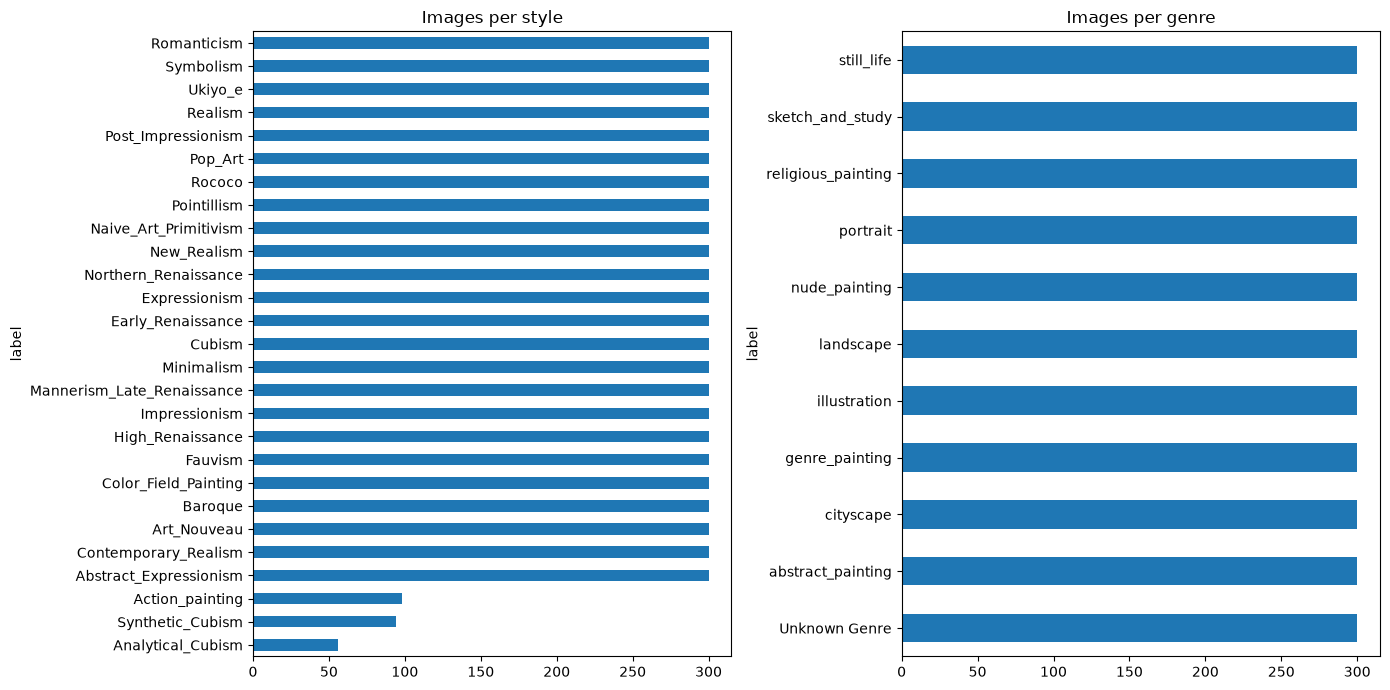

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

style_meta["label"].value_counts().sort_values().plot.barh(ax=axes[0], title="Images per style")
genre_meta["label"].value_counts().sort_values().plot.barh(ax=axes[1], title="Images per genre")

plt.tight_layout()
plt.show()

In [10]:
for name, meta in [("styles", style_meta), ("genres", genre_meta)]:
    is_unknown = meta["artist"] == "Unknown Artist"
    unknown_share = is_unknown.mean() * 100
    n_named_artists = meta.loc[~is_unknown, "artist"].nunique()
    print(f"{name}: {n_named_artists} named artists, {unknown_share:.0f}% Unknown Artist")

styles: 105 named artists, 81% Unknown Artist
genres: 128 named artists, 46% Unknown Artist


In [11]:
style_meta["is_unknown"] = style_meta["artist"] == "Unknown Artist"
(style_meta.groupby("label")["is_unknown"].mean() * 100).round(0).sort_values()

label
Synthetic_Cubism                9.0
Analytical_Cubism              16.0
Pointillism                    57.0
Impressionism                  65.0
Realism                        66.0
Mannerism_Late_Renaissance     67.0
High_Renaissance               68.0
Baroque                        72.0
Romanticism                    73.0
Northern_Renaissance           73.0
Post_Impressionism             75.0
Symbolism                      77.0
Art_Nouveau                    80.0
Early_Renaissance              80.0
Ukiyo_e                        81.0
Color_Field_Painting           87.0
Expressionism                  87.0
Fauvism                        89.0
Rococo                         94.0
Naive_Art_Primitivism          95.0
Cubism                         95.0
Abstract_Expressionism         97.0
Contemporary_Realism           98.0
Pop_Art                        99.0
Minimalism                    100.0
Action_painting               100.0
New_Realism                   100.0
Name: is_unknown, dtyp

In [ ]:
from PIL import Image


def show_samples(meta, subset_dir, title):
    classes = sorted(meta["label"].unique())
    n_cols = 6
    n_rows = -(-len(classes) // n_cols)  # number of rows, rounded up
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.2 * n_cols, 2.4 * n_rows))
    for ax in axes.flat:
        ax.axis("off")
    for ax, cls in zip(axes.flat, classes):
        path = meta.loc[meta["label"] == cls, "path"].sample(1, random_state=0).iloc[0]
        ax.imshow(Image.open(DATA_DIR / subset_dir / path))
        ax.set_title(cls, fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


show_samples(style_meta, "wikiart_style_all", "One sample per style")
show_samples(genre_meta, "wikiart_genre_all", "One sample per genre")